# AP 155 Lab Exercise
---
## Exercise 7: Root Finding

_Instructions_: 
- **Report figure:** (See Problem) Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).
- **Report discussion:**
    - Explain the report figure.
    - What are the advantages and disadvantages of the root-finding methods?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: de Vera, Clarence Joseph
- _Student No._: 2024-11757
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

**Explain the report figure.**
The figure plots the ($x_i$) versus ($i$) for the root near $x \approx -1.19$. By creating a convergence plot, the four root-finding methods are easily compared. Newton's method and Secant method are the fastest, flattening out to the root with the fewest iterations. The Bisection method constantly halves the interval, creating a jagged pattern and reaching the root after a few more iterations than the Newton's and Secant methods. The Fixed-Point method forms a slow, smooth curve towards the root, taking the most iterations for it to flatten out completely.

**What are the advantages and disadvantages of the root-finding methods?**

Fixed-point: Easy to code and needs only one guess, but is very sensitive to the chosen omega. Choosing the wrong omega causes the calculation to diverge.

Bisection: Very reliable and guaranteed to find a root if the bounds bracket it, but it converges slower.

Newton's Method: Quick convergence for normal roots. However, it requires manually coding the exact derivative. Also, a bad initial guess or a flat slope (like the double root at $x=2.0$) can cause it to go to the wrong root.

Secant Method: Fast and does not need an exact derivative, but it requires two good initial guesses. If the initial guesses are too far apart, the secant line might point toward a completely different root on the graph.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Root Finding


Implement root finders *manually* to find the roots of an arbitrary function

1. fixed-point method (relaxation, needs an initial guess)
2. bisection method (bracketing, needs two bounds)
3. newton's method (known derivative, needs an initial guess)
4. secant method (approximate derivative, needs two initial guesses)

Consider the function

$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8
$$

5. Plot the function from x=-2 to x=5. You may want to "enlarge" the plot by rescaling/"cropping" the y-axis. You should be able to estimate where the roots are approximately
   
6. Find the roots of $f(x)$ by implementing the four methods shown.

7. Report Figure: Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

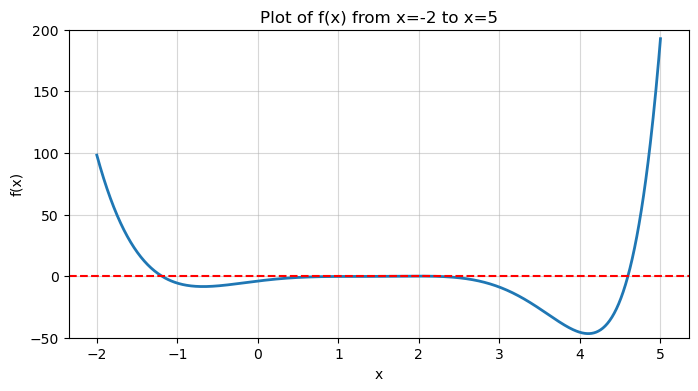

All Roots (using Newton's root-finding method)
Root 1 (guess = -1.0): -1.192686
Root 2 (guess = 1.5): 2.000480
Root 3 (guess = 5.0): 4.595864


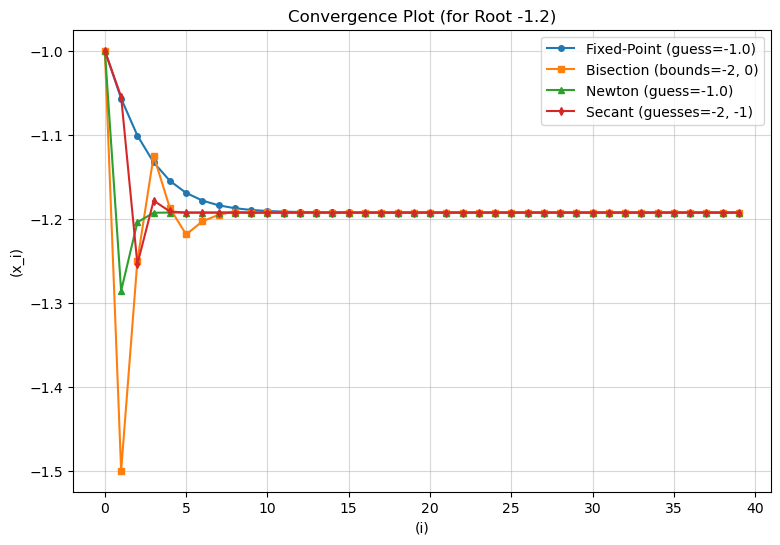

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# f(x)
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + (x**2)*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

# f'(x)
def df(x):
    return -5*x**4 + 16*x**3 - 12*x**2 - 4*x + 8 + np.exp(x)*(x**2 - 2*x)

# [-2, 5] plot
x_vals = np.linspace(-2, 5, 1000)
y_vals = f(x_vals)

plt.figure(figsize=(8, 4))
plt.plot(x_vals, y_vals, linewidth=2)
plt.axhline(0, color='r', linestyle='--')
plt.ylim(-50, 200) 
plt.grid(True, alpha=0.5)
plt.title("Plot of f(x) from x=-2 to x=5")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()


tol = 1e-6
max_iters = 40
print("All Roots (using Newton's root-finding method)")

# fixed-point method
history_fixed = []
x_fixed = -1.0
omega = 0.01 
for i in range(max_iters):
    history_fixed.append(x_fixed)
    if abs(f(x_fixed)) > tol:
        x_fixed = x_fixed + omega * f(x_fixed)

# bisection method
history_bisect = []
a, b = -2.0, 0.0
for i in range(max_iters):
    mid = (a + b) / 2.0
    history_bisect.append(mid)
    if abs(f(mid)) > tol:
        if f(a) * f(mid) < 0:
            b = mid
        else:
            a = mid

# newton's method
history_newton = []
x_newt = -1.0
for i in range(max_iters):
    history_newton.append(x_newt)
    if abs(f(x_newt)) > tol:
        x_newt = x_newt - f(x_newt) / df(x_newt)

# secant method
history_secant = []
x0, x1 = -2.0, -1.0
for i in range(max_iters):
    history_secant.append(x1)
    if abs(f(x1)) > tol and abs(x1 - x0) > tol:
        x_next = x1 - f(x1) * (x1 - x0) / (f(x1) - f(x0))
        x0 = x1
        x1 = x_next
        
print(f"Root 1 (guess = -1.0): {x_newt:.6f}")

# root 2 and 3 using newton's method
x_root2 = 1.5 
for i in range(max_iters):
    if abs(f(x_root2)) > tol:
        x_root2 = x_root2 - f(x_root2) / df(x_root2)
print(f"Root 2 (guess = 1.5): {x_root2:.6f}")

x_root3 = 5.0 
for i in range(max_iters):
    if abs(f(x_root3)) > tol:
        x_root3 = x_root3 - f(x_root3) / df(x_root3)
print(f"Root 3 (guess = 5.0): {x_root3:.6f}")

# convergence plot
plt.figure(figsize=(9, 6))
plt.plot(history_fixed, marker='o', markersize=4, label='Fixed-Point (guess=-1.0)')
plt.plot(history_bisect, marker='s', markersize=4, label='Bisection (bounds=-2, 0)')
plt.plot(history_newton, marker='^', markersize=4, label='Newton (guess=-1.0)')
plt.plot(history_secant, marker='d', markersize=4, label='Secant (guesses=-2, -1)')

plt.title("Convergence Plot (for Root -1.2)")
plt.xlabel("(i)")
plt.ylabel("(x_i)")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

#### Problem 1 code summary

This script defines the function $f(x)$ and its derivative, then graphs the function from $-2$ to $5$ to give an estimate of where the roots are. It then implements the fixed-point, bisection, Newton's, and secant algorithms using for loops. Once a method gets very close to 0 (tol), the math stops updating but the loop continues appending the final answer so all arrays reach exactly 40 steps, which makes the convergence plot look clean for me to compare each root-finding method. I used Newton's root-finding method to get the other roots since (I think) it's the best root-finding method.

---